# The validation battery on a ladder of models: discrimination, calibration and stability

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic, and notebook 04 of topic 01
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- read the committed battery of C01, 187 test rows on eight models, as one table: which of the 15 test ids carry a threshold and which only describe, and which rows belong to the portfolio and which to a grade;
- recompute a grade-level row, a portfolio-level row and a Hosmer-Lemeshow statistic from the committed grade and reliability tables, and show that they equal the committed rows;
- read discrimination (AUC, DeLong against the scorecard, AUC against development), calibration (level and fit tests) and stability (PSI) together, and say why the same model can be green on one family and amber on another;
- see which tests catch a drift of the inputs and which catch a shift of the default rate, using the two shifted variants.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))


riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The case is C01 again: the 9,000 held-out Taiwan cards scored by the eight models of the ladder (UCI Taiwan, Yeh 2009, CC BY 4.0, licence class `mirror-allowed`, https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients). Three committed files hold the battery:

- `data/derived/C01/holdout.json`: the ladder (`model`), the battery (`tests`, one row per test, model and segment), and per model the grade table, the reliability bins and the ROC (`outputs.rungs`).
- `data/derived/C01/drift-moderate.json` and `data/derived/C01/prior-shift.json`: the same models and the same battery on the same cards after a **synthetic perturbation of the evaluation set only**: a moderate drift of the inputs, and a prior shift that multiplies the default rate by 1.5 (the case design in `docs/design/SDD.md`: the shifts are labelled synthetic and never touch the fit). They show what each test notices.

The next cell loads the three files and prints the rungs, with the title the file gives in this language.

In [2]:
# Load the three committed files and print the rungs of the ladder
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C01"
holdout = json.loads((derived / "holdout.json").read_text(encoding="utf-8"))
drift = json.loads((derived / "drift-moderate.json").read_text(encoding="utf-8"))
prior = json.loads((derived / "prior-shift.json").read_text(encoding="utf-8"))

LANG = "en"
# The engine's light values, named in this language
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "none"}
rungs = [m["id"] for m in holdout["model"]]
for m in holdout["model"]:
    print(f"{m['id']:14s} {m['title'][LANG]}")
print("baked by riskvalidation", holdout["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
for name, doc in (("holdout", holdout), ("drift-moderate", drift), ("prior-shift", prior)):
    print(f"{name:15s} cards {doc['outputs']['n']} | defaults {doc['outputs']['defaults']} | test rows {len(doc['tests'])}")


P0-constant    Constant PD
P0-single      Single variable (PAY_0)
P1-scorecard   WoE logistic scorecard
P2a-l1         L1 logistic regression on WoE
P2b-pltr       Penalised logistic tree regression (PLTR)
P3-ebm         Explainable boosting machine (GA2M)
P4-lightgbm    Monotone gradient boosting (LightGBM)
P4-xgboost     Monotone gradient boosting (XGBoost cross-check)
baked by riskvalidation 0.4.3 | installed 0.9.0
holdout         cards 9000 | defaults 1991 | test rows 187
drift-moderate  cards 9000 | defaults 2316 | test rows 186
prior-shift     cards 9000 | defaults 2986 | test rows 186


## Method

### Step 1: one table of tests, two kinds of row

Every row of `tests` is one `TestResult` of the engine: a test id, a model, a segment, the statistic, the p-value or the metric, and the light the policy gave. The **segment** says what the row is about: `portfolio` for the whole holdout, a grade (`G05`, `G06`, ...) for the cards of one grade, and `characteristic:<name>` for one input variable of the stability tests. The **policy** decides which tests have a light: a test with a threshold is coloured from its p-value (amber below 0.05, red below 0.01 in the default policy); a descriptive test (AUC, KS, Brier, ECE) measures and gets no light, because the ECB instructions and the working paper that define them set no thresholds. The next cell counts the committed rows by test and by kind of segment, and marks which tests the default policy holds a threshold for.

In [3]:
# Count the committed rows by test id and by kind of segment, and mark the tests the default policy holds a threshold for
policy = rv.default_policy()
tests = holdout["tests"]


def kind_of(segment):
    return "portfolio" if segment == "portfolio" else ("characteristic" if segment.startswith("characteristic:") else "grade")


ids = sorted({t["test_id"] for t in tests})
print(f"{'test':22s} {'rows':>5s} {'portfolio':>9s} {'grade':>7s} {'char.':>7s}  threshold in the policy")
for test_id in ids:
    rows = [t for t in tests if t["test_id"] == test_id]
    counts = [sum(kind_of(t["segment"]) == k for t in rows) for k in ("portfolio", "grade", "characteristic")]
    print(f"{test_id:22s} {len(rows):5d} {counts[0]:9d} {counts[1]:7d} {counts[2]:7d}  {test_id in policy.thresholds}")
print("rows in total:", len(tests), "| test ids:", len(ids), "| models:", len(rungs))


test                    rows portfolio   grade   char.  threshold in the policy
disc.auc                   8         8       0       0  False
disc.auc_vs_initial        7         7       0       0  True
disc.delong                6         6       0       0  True
disc.ks                    7         7       0       0  False
pd.binomial                8         8       0       0  True
pd.binomial_vasicek        8         8       0       0  True
pd.brier                   8         8       0       0  False
pd.chi2_grades             7         7       0       0  True
pd.ece                     8         8       0       0  False
pd.hosmer_lemeshow         7         7       0       0  True
pd.jeffreys               70         8      62       0  True
pd.spiegelhalter           8         8       0       0  True
rating.hhi                 8         8       0       0  True
stability.csi             20         0       0      20  True
stability.psi              7         7       0       0  True
r

### Step 2: the portfolio rows of all eight models

The portfolio-level rows are the headline of the battery. The next cell prints, for each test, the p-value (or the metric when the test is descriptive) and the first letters of the light for each rung, and the figure draws the lights as a grid: green, amber, red, and grey for a descriptive row. Two things are worth looking for before reading any number: the rows are not equally informative (descriptive ones are grey by design), and the lights of one test do not move together with another's.

In [4]:
# Print the portfolio rows: p-value or metric and light, per test and rung
def portfolio_row(doc, test_id, model_id):
    return next((t for t in doc["tests"] if t["test_id"] == test_id and t["model_id"] == model_id and t["segment"] == "portfolio"), None)


board = [i for i in ids if i != "stability.csi"]
print(f"{'':22s}" + "".join(f"{r.split('-')[0]:>14s}" for r in rungs))
for test_id in board:
    cells_ = []
    for r in rungs:
        row = portfolio_row(holdout, test_id, r)
        if row is None:
            cells_.append(f"{'-':>14s}")
        else:
            value = row["p_value"] if row["p_value"] is not None else row["metric"]
            cells_.append(f"{value:11.3g}/{LIGHT[row['light']][:3]}")
    print(f"{test_id:22s}" + "".join(cells_))


                                  P0            P0            P1           P2a           P2b            P3            P4            P4
disc.auc                      0.5/non      0.692/non      0.759/non      0.759/non      0.775/non      0.775/non      0.777/non      0.775/non
disc.auc_vs_initial                -      0.168/gre      0.226/gre      0.225/gre      0.533/gre      0.347/gre      0.132/gre      0.213/gre
disc.delong                        -   1.26e-40/red             -     0.0884/gre   2.58e-11/red   2.74e-10/red   6.53e-13/red   2.18e-12/red
disc.ks                            -  2.31e-179/non  8.14e-220/non  8.27e-220/non  2.54e-248/non  1.55e-253/non  1.62e-246/non  2.69e-249/non
pd.binomial                 0.501/gre      0.269/gre      0.314/gre      0.319/gre      0.312/gre      0.782/gre      0.824/gre      0.839/gre
pd.binomial_vasicek          0.47/gre       0.45/gre      0.454/gre      0.455/gre      0.454/gre      0.493/gre      0.497/gre      0.498/gre
pd.brier   

The figure draws the same table as a grid of lights, one column per model and one row per test.

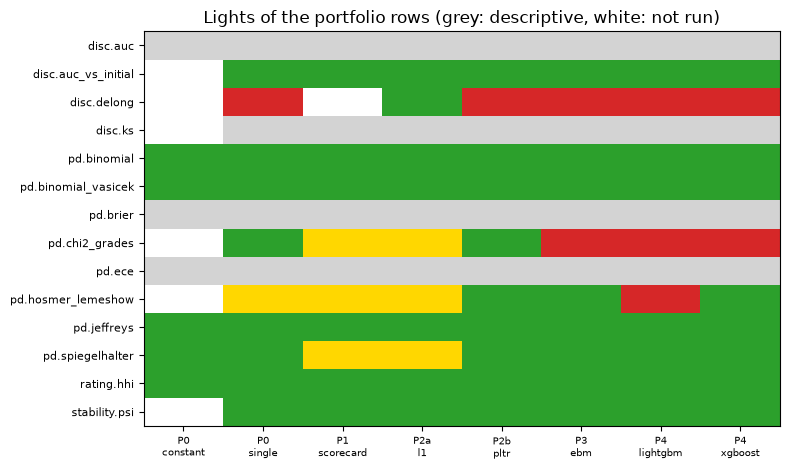

In [5]:
# Draw the lights of the portfolio rows as a grid
from matplotlib.colors import ListedColormap

codes = {"missing": 0, "not_evaluated": 1, "green": 2, "amber": 3, "red": 4}
grid = np.zeros((len(board), len(rungs)))
for i, test_id in enumerate(board):
    for j, r in enumerate(rungs):
        row = portfolio_row(holdout, test_id, r)
        grid[i, j] = codes["missing"] if row is None else codes[row["light"]]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.imshow(grid, cmap=ListedColormap(["white", "lightgray", "tab:green", "gold", "tab:red"]), vmin=0, vmax=4, aspect="auto")
ax.set_xticks(range(len(rungs)))
ax.set_xticklabels([r.split("-")[0] + "\n" + r.split("-")[-1] for r in rungs], fontsize=7)
ax.set_yticks(range(len(board)))
ax.set_yticklabels(board, fontsize=8)
ax.set_title("Lights of the portfolio rows (grey: descriptive, white: not run)")
fig.tight_layout()
plt.show()


### Step 3: discrimination

The first family asks whether the PD ranks defaulters above non-defaulters. Three tests belong to it. The AUC is descriptive. The **DeLong test** (DeLong, DeLong and Clarke-Pearson, 1988) compares the AUC of two models scored on the same cards, which are correlated, so it needs the covariance of the two curves; its statistic is the AUC difference over its standard error:

$$z = \frac{\widehat{\mathrm{AUC}}_1 - \widehat{\mathrm{AUC}}_2}{\sqrt{\widehat{\mathrm{Var}}(\widehat{\mathrm{AUC}}_1 - \widehat{\mathrm{AUC}}_2)}}$$

and the p-value is two-sided on a standard normal. The committed rows carry the two AUCs, their difference and its variance in `extras`. The next cell prints them and recomputes $z$ and the p-value from those numbers. It also shows against which model each row compares: the second AUC is the scorecard's in every row. Then the **AUC against development** (ECB 2019, section 2.5.4.1): one-sided, it rejects when the AUC fell since development; the committed rows add the development AUC's variance to the statistic, an extension the engine notes in its `notes` field.

In [6]:
# Recompute the DeLong statistic and p-value of each committed row from its AUCs and the variance of their difference
print(f"{'model':14s} {'AUC 1':>7s} {'AUC 2':>7s} {'diff.':>8s} {'z':>7s} {'z recomputed':>16s} {'p committed':>14s} {'p recomputed':>14s}")
for r in rungs:
    row = portfolio_row(holdout, "disc.delong", r)
    if row is None:
        continue
    e = row["extras"]
    z = e["difference"] / np.sqrt(e["variance"])
    print(f"{r:14s} {e['auc_1']:7.4f} {e['auc_2']:7.4f} {e['difference']:8.4f} {row['statistic']:7.2f} {z:16.2f} {row['p_value']:14.3g} {2 * stats.norm.sf(abs(z)):14.3g}")


model            AUC 1   AUC 2    diff.       z     z recomputed    p committed   p recomputed
P0-single       0.6917  0.7587  -0.0670  -13.35           -13.35       1.26e-40       1.26e-40
P2a-l1          0.7587  0.7587  -0.0000   -1.70            -1.70         0.0884         0.0884
P2b-pltr        0.7749  0.7587   0.0162    6.67             6.67       2.58e-11       2.58e-11
P3-ebm          0.7746  0.7587   0.0159    6.31             6.31       2.74e-10       2.74e-10
P4-lightgbm     0.7770  0.7587   0.0183    7.19             7.19       6.53e-13       6.53e-13
P4-xgboost      0.7755  0.7587   0.0168    7.02             7.02       2.18e-12       2.18e-12


The AUC against development. The next cell recomputes the statistic of the scorecard from the committed extras, and then calls the engine's two discrimination tests on the 50-card sample: the AUC against development with the committed development AUC and variance, and DeLong between the boosting machine's score and the scorecard's PD.

In [7]:
# The AUC against development: recompute the statistic of the scorecard from the committed extras, then call the engine on the 50-card sample
row = portfolio_row(holdout, "disc.auc_vs_initial", "P1-scorecard")
e = row["extras"]
z = (e["auc_initial"] - e["auc_current"]) / np.sqrt(e["s2_total"])
print("AUC at development:", round(e["auc_initial"], 4), "| AUC now:", round(e["auc_current"], 4))
print("variance of the current AUC:", f"{e['s2']:.3g}", "| of the development AUC:", f"{e['auc_initial_variance']:.3g}", "| total:", f"{e['s2_total']:.3g}")
print("z recomputed:", round(float(z), 4), "| committed:", round(row["statistic"], 4), "| p one-sided:", round(float(stats.norm.sf(z)), 4), "| committed:", round(row["p_value"], 4))

from riskvalidation.validation import disc_auc_vs_initial, disc_delong

sample = holdout["outputs"]["sample"]
y50 = np.array(sample["targets"])
pd50 = np.array(sample["scorecard_pd"])
ebm50 = np.array(sample["ebm_logit"])
small = disc_auc_vs_initial(e["auc_initial"], pd50, y50, auc_initial_variance=e["auc_initial_variance"], policy=policy, model_id="P1-scorecard")
print("engine on 50 cards, AUC against development: p", round(small.p_value, 4), "|", LIGHT[small.light.value])
duo = disc_delong(ebm50, pd50, y50, policy=policy, model_id="P3-ebm")
print("engine on 50 cards, DeLong EBM against scorecard: AUC", round(duo.extras["auc_1"], 4), "against", round(duo.extras["auc_2"], 4), "| p", round(duo.p_value, 3), "|", LIGHT[duo.light.value])


AUC at development: 0.7673 | AUC now: 0.7587
variance of the current AUC: 4.17e-05 | of the development AUC: 8.78e-05 | total: 0.000129
z recomputed: 0.7529 | committed: 0.7529 | p one-sided: 0.2257 | committed: 0.2257
engine on 50 cards, AUC against development: p 0.5476 | green
engine on 50 cards, DeLong EBM against scorecard: AUC 0.7695 against 0.7752 | p 0.866 | green


### Step 4: calibration, the level and the fit

The second family asks whether the PDs have the right size. They are two questions, and the battery asks both:

- **the level**: is the average PD right for the portfolio? The Jeffreys test, the binomial test and the Vasicek-adjusted binomial test take the count of cards, the count of defaults and the mean PD (notebook 03 of topic 01). They are one-sided: they reject when defaults exceed what the PD allows.
- **the fit**: does the PD fit the outcomes group by group? The chi-square over grades (BCBS Working Paper 14), Hosmer-Lemeshow and Spiegelhalter ask it, and can fail even when the average is right, because a PD that is too high for some obligors and too low for others cancels in the average.

The next cell takes the 12 grades of the scorecard that the holdout artifact commits, drops the empty ones, and calls the engine on them. The Jeffreys test runs once per grade (the `G05`, `G06`, ... rows) and the chi-square runs once over all grades (the `portfolio` row). Both are compared with the committed rows.

In [8]:
# Call the engine on the committed grade table and compare with the committed grade-level and portfolio-level rows
from riskvalidation.validation import pd_chi2_grades, pd_jeffreys

grades = [g for g in holdout["outputs"]["rungs"]["P1-scorecard"]["grades"] if g["n"] > 0]
print(f"{'grade':7s} {'cards':>7s} {'defaults':>9s} {'mean PD':>8s} {'p engine':>11s} {'p committed':>14s} {'light':>6s}")
for g in grades:
    result = pd_jeffreys(n=g["n"], d=g["d"], pd=g["pd"], policy=policy, model_id="P1-scorecard", segment=g["grade"])
    committed = next(t for t in tests if t["test_id"] == "pd.jeffreys" and t["model_id"] == "P1-scorecard" and t["segment"] == g["grade"])
    print(f"{g['grade']:7s} {g['n']:7d} {g['d']:9d} {g['pd']:8.4f} {result.p_value:11.4f} {committed['p_value']:14.4f} {LIGHT[result.light.value]:>6s}")

chi = pd_chi2_grades([g["n"] for g in grades], [g["d"] for g in grades], [g["pd"] for g in grades], policy=policy, model_id="P1-scorecard", segment="portfolio")
chi_committed = portfolio_row(holdout, "pd.chi2_grades", "P1-scorecard")
print("chi-square over grades: T", round(chi.statistic, 4), "| degrees of freedom", chi.extras["dof"], "| p", round(chi.p_value, 4), "| committed", round(chi_committed["p_value"], 4), "|", LIGHT[chi.light.value])


grade     cards  defaults  mean PD    p engine    p committed  light
G05          68         4   0.0468      0.2953         0.2953  green
G06         698        54   0.0653      0.1005         0.1005  green
G07        1862       155   0.0950      0.9607         0.9607  green
G08        3101       466   0.1399      0.0494         0.0494  amber
G09        1224       251   0.1990      0.2957         0.2957  green
G10         719       251   0.3241      0.0770         0.0770  green
G11         510       251   0.4762      0.2348         0.2348  green
G12         818       559   0.7243      0.9952         0.9952  green
chi-square over grades: T 17.3737 | degrees of freedom 8 | p 0.0264 | committed 0.0264 | amber


### Step 5: Hosmer-Lemeshow, opened

Hosmer-Lemeshow sorts the cards by PD, cuts them into $G$ groups of equal size and compares, in group $g$ with $m_g$ cards, the observed defaults $O_g$ with the expected defaults $E_g$ (the sum of the PDs of the group; Hosmer and Lemeshow, 1980):

$$\mathrm{HL} = \sum_{g=1}^{G} \frac{(O_g - E_g)^2}{E_g\,(1 - E_g / m_g)}$$

The reference distribution is $\chi^2$ with $G$ degrees of freedom when the PDs were set before the outcomes, as for a validation sample (the committed row has `fitted` false and 10 degrees of freedom). The reliability bins of the artifact are exactly such groups: ten bins of 900 cards by PD, each with its mean PD and observed default rate. The next cell builds $O_g$ and $E_g$ from them, prints every term, and compares the sum and its p-value with the committed row.

In [9]:
# Rebuild the Hosmer-Lemeshow statistic from the ten reliability bins, term by term
reliability = holdout["outputs"]["rungs"]["P1-scorecard"]["reliability"]
m_g = np.array([b["n"] for b in reliability], dtype=float)
expected = np.array([b["pd"] for b in reliability]) * m_g
observed = np.array([b["dr"] for b in reliability]) * m_g
terms = (observed - expected) ** 2 / (expected * (1.0 - expected / m_g))
print(f"{'g':>2s} {'m_g':>5s} {'O_g':>7s} {'E_g':>7s} {'term':>8s}")
for g_, (m_, o_, e_, t_) in enumerate(zip(m_g, observed, expected, terms), start=1):
    print(f"{g_:2d} {m_:5.0f} {o_:7.1f} {e_:7.1f} {t_:8.3f}")
hl_row = portfolio_row(holdout, "pd.hosmer_lemeshow", "P1-scorecard")
print("HL from the bins:", round(float(terms.sum()), 4), "| committed:", round(hl_row["statistic"], 4))
print("p (chi2, 10 degrees of freedom):", round(float(stats.chi2.sf(terms.sum(), hl_row["extras"]["dof"])), 4), "| committed:", round(hl_row["p_value"], 4), "|", LIGHT[hl_row["light"]])


 g   m_g     O_g     E_g     term
 1   900    68.0    59.1    1.430
 2   900    73.0    79.0    0.503
 3   900    77.0    95.8    4.142
 4   900   105.0   110.6    0.321
 5   900   140.0   123.7    2.496
 6   900   140.0   136.4    0.110
 7   900   187.0   157.0    6.922
 8   900   225.0   211.5    1.133
 9   900   367.0   359.8    0.240
10   900   609.0   638.6    4.723
HL from the bins: 22.0205 | committed: 22.0205
p (chi2, 10 degrees of freedom): 0.015 | committed: 0.015 | amber


The reliability diagram of the scorecard and of the calibrated LightGBM rung: the ten bins of 900 cards, mean PD against observed default rate, with the diagonal as the perfect calibration.

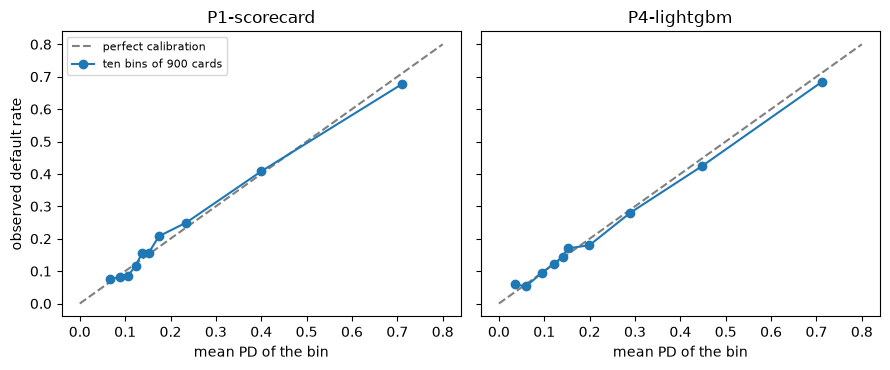

In [10]:
# Draw the reliability diagram of the scorecard and of the calibrated LightGBM rung
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, rung in zip(axes, ("P1-scorecard", "P4-lightgbm")):
    bins_ = holdout["outputs"]["rungs"][rung]["reliability"]
    ax.plot([0, 0.8], [0, 0.8], color="gray", linestyle="--", label="perfect calibration")
    ax.plot([b["pd"] for b in bins_], [b["dr"] for b in bins_], marker="o", label="ten bins of 900 cards")
    ax.set_xlabel("mean PD of the bin")
    ax.set_title(rung)
axes[0].set_ylabel("observed default rate")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()


The Brier score and the expected calibration error (ECE) summarise the same bins in one number each and are descriptive in the default policy. The Brier score is the mean squared error of the PD as a forecast; the ECE is the weighted mean absolute gap between the mean PD and the observed rate per bin. The next cell prints both for the eight rungs, with the engine's own flag on whether the Brier decomposition into reliability, resolution and uncertainty is exact (it is not for continuous PDs).

In [11]:
# Print the Brier score and the expected calibration error of the eight rungs
print(f"{'model':14s} {'Brier':>7s} {'ECE':>7s} {'exact decomposition':>26s}")
for r in rungs:
    brier = portfolio_row(holdout, "pd.brier", r)
    ece = portfolio_row(holdout, "pd.ece", r)
    print(f"{r:14s} {brier['metric']:7.4f} {ece['metric']:7.4f} {str(brier['extras']['decomposition_exact']):>26s}")


model            Brier     ECE        exact decomposition
P0-constant     0.1723  0.0174                       True
P0-single       0.1431  0.0144                      False
P1-scorecard    0.1393  0.0155                      False
P2a-l1          0.1393  0.0153                      False
P2b-pltr        0.1367  0.0113                      False
P3-ebm          0.1367  0.0118                      False
P4-lightgbm     0.1361  0.0134                      False
P4-xgboost      0.1359  0.0124                      False


### Step 6: stability

The third family compares the population now with the population at development. The population stability index (PSI) of the PD distribution takes ten bins fixed on the development cards, here the 16,800 training cards, and compares the share of the 9,000 holdout cards in each; with the chi-square benchmark of Yurdakul and Naranjo (2020) it has a p-value, and `benchmark_05` is the PSI above which it would reject at 5%. The same index on every input variable is the characteristic stability index (CSI), one row per variable. The Herfindahl index of the grades (`rating.hhi`) asks whether the grades concentrate more than at development. The next cell prints the scorecard's PSI with its contributions per bin, the lights of the 20 CSI rows and the concentration row.

In [12]:
# Print the PSI with its contributions per bin, the CSI lights and the concentration row of the scorecard
psi = portfolio_row(holdout, "stability.psi", "P1-scorecard")
e = psi["extras"]
print("PSI:", round(psi["metric"], 6), "| p:", round(psi["p_value"], 4), "|", LIGHT[psi["light"]], "| 5% critical PSI:", round(e["benchmark_05"], 5))
print("development cards:", e["n"], "| holdout cards:", e["m"], "| bins:", e["bins"])
print("contribution per bin:", [round(c, 5) for c in e["contributions"]])
csi = [t for t in tests if t["test_id"] == "stability.csi"]
lights = {}
for t in csi:
    lights[LIGHT[t["light"]]] = lights.get(LIGHT[t["light"]], 0) + 1
print("CSI: ", len(csi), "rows, lights", lights)
hhi = portfolio_row(holdout, "rating.hhi", "P1-scorecard")
print("grade concentration, Herfindahl index now and at development:", round(hhi["extras"]["hi_current"], 4), round(hhi["extras"]["hi_initial"], 4), "| p", round(hhi["p_value"], 3), "|", LIGHT[hhi["light"]])


PSI: 0.000952 | p: 0.7812 | green | 5% critical PSI: 0.00289
development cards: 16800 | holdout cards: 9000 | bins: 10
contribution per bin: [0.0002, 0.0, 0.0, 0.00027, 0.0, 0.00017, 7e-05, 0.0, 0.00018, 6e-05]
CSI:  20 rows, lights {'green': 20}
grade concentration, Herfindahl index now and at development: 0.3602 0.3588 | p 0.497 | green


### Step 7: what each test notices

The same scorecard, the same battery, three evaluation sets: the holdout as it is, the holdout with a moderate drift of the inputs, and the holdout with the default rate multiplied by 1.5. The next cell puts the scorecard's portfolio rows side by side. A battery is useful only if its tests notice different things, and this table is the evidence of which notice what.

In [13]:
# Put the portfolio rows of the scorecard side by side on the three evaluation sets
variants = (("holdout", holdout), ("drift-moderate", drift), ("prior-shift", prior))
print(f"{'test':22s}" + "".join(f"{name:>20s}" for name, _ in variants))
for test_id in board:
    line = f"{test_id:22s}"
    for _, doc in variants:
        row = portfolio_row(doc, test_id, "P1-scorecard")
        if row is None:
            line += f"{'-':>20s}"
            continue
        value = row["p_value"] if row["p_value"] is not None else row["metric"]
        line += f"{value:14.3g}/{LIGHT[row['light']][:3]:<4s}"
    print(line)
print("defaults:", {name: doc["outputs"]["defaults"] for name, doc in variants})


test                               holdout      drift-moderate         prior-shift
disc.auc                       0.759/non          0.784/non          0.769/non 
disc.auc_vs_initial            0.226/gre          0.938/gre          0.558/gre 
disc.delong                              -                   -                   -
disc.ks                    8.14e-220/non      5.54e-321/non      4.98e-311/non 
pd.binomial                    0.314/gre          0.732/gre       1.08e-78/red 
pd.binomial_vasicek            0.454/gre          0.493/gre           0.09/gre 
pd.brier                       0.139/non          0.147/non           0.18/non 
pd.chi2_grades                0.0264/amb       5.57e-05/red      3.09e-108/red 
pd.ece                        0.0155/non         0.0143/non         0.0879/non 
pd.hosmer_lemeshow             0.015/amb        0.00163/red      2.19e-109/red 
pd.jeffreys                     0.31/gre          0.728/gre       8.67e-79/red 
pd.spiegelhalter              0.02

## Results

- **The battery is one table with two kinds of row.** 187 rows on eight models and 15 test ids: 105 at portfolio level, 62 at grade level (the Jeffreys test per grade) and 20 for the characteristic stability of the inputs. Eleven test ids have a threshold in the default policy; AUC, KS, Brier and ECE only describe.
- **The committed rows are the engine's rows.** Called on the committed grade table, the engine returns the same Jeffreys p-value for each of the eight grades and the same chi-square over grades (T about 17.4 on 8 degrees of freedom, p 0.026); the Hosmer-Lemeshow statistic rebuilt term by term from the ten reliability bins is 22.02, the committed value, with p 0.015 on 10 degrees of freedom.
- **Ranking and size are different questions.** The scorecard ranks as well as the logistic model with a penalty (P2a: DeLong p 0.09, no difference) and worse than the four richer models: the penalised trees, the explainable boosting machine and the two boosted-tree models raise the AUC by 0.016 to 0.018, and DeLong is red against the scorecard for all four. Yet on the level all models are green: the Jeffreys, binomial and Vasicek tests accept the average PD of every rung.
- **The fit tests disagree with the level tests, and among themselves.** The scorecard is green on the level, amber on Hosmer-Lemeshow, Spiegelhalter and the chi-square over grades: the average is right and some grades are not (the Jeffreys test finds G08 amber, p 0.049). The explainable boosting machine and the two boosted rungs are the opposite case for the chi-square over grades (red, p 0.0007 or below), while their Spiegelhalter test is green and only LightGBM is red on Hosmer-Lemeshow. The tests answer different questions, and a validator reads them together before concluding that "the calibration is off".
- **Stability is quiet on the holdout and loud on the shifts.** The PSI of the scorecard is 0.00095, below its 5% critical value 0.0029, and the 20 CSI rows say nothing changed, as expected for a random holdout. With the drifted inputs the PSI is red (p about 3e-36) and the fit tests fall (chi-square and Hosmer-Lemeshow red), but the level tests stay green and the AUC against development stays green; with the default rate multiplied by 1.5 the level tests (Jeffreys, binomial) turn red at once, and the Vasicek-adjusted binomial stays green (p 0.09), the price of allowing for correlation being power.

What this notebook does not show: the thresholds are the default policy's convention (notebook 03 of topic 01), not regulation, so an amber is a flag and not a verdict. The 62 per-grade rows are Jeffreys tests of grades with a few hundred cards each, and the test has little power there. The `small-sample` and `label-noise` variants and the German twin are further variants of the same battery.

## Summary

- One battery, 15 test ids, eight models: portfolio rows carry the headline, grade rows locate the problem, characteristic rows watch the inputs.
- A committed row is reproducible: the engine returns it from the grade table, and Hosmer-Lemeshow follows from ten reliability bins with the formula in this notebook.
- Discrimination, level, fit and stability are separate families; a model can be green on one and amber on another, and the DeLong test, not the AUC alone, says whether a challenger ranks better.
- The shifted variants show that the tests notice different shifts: a drift of the inputs reaches the PSI and the fit tests, a shift of the default rate reaches the level tests first.

**What to try next.** Read the same table for `small-sample.json` and compare the fit tests with the holdout: what changes when the sample is smaller? Then continue with notebook 04, which validates out of time.

## References

- DeLong, E. R., DeLong, D. M. and Clarke-Pearson, D. L. (1988), Comparing the areas under two or more correlated receiver operating characteristic curves: a nonparametric approach, Biometrics 44(3). https://doi.org/10.2307/2531595
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Yurdakul, B. and Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): the binomial, the Vasicek-adjusted binomial and the chi-square over grades. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sections 2.5.3.1 and 2.5.4.1 and Annex 1 (section 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients